# MNIST Handwritten Digits Recogniton
In this demo, we will perform a single digit recognition using MNIST dataset and neural network model in Tensorflow.  
# Loading MNIST training data

In [15]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
print('TensorFlow version:', tf.__version__)

mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0


TensorFlow version: 2.18.1


## Training Images
![mnist.train.xs](...%0Agg==)

In [16]:
# check MNIST training images matrix shape
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

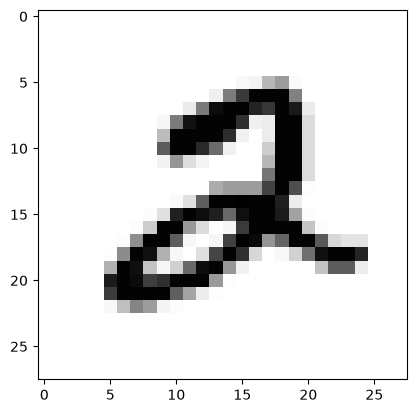

In [17]:
# plot a sample image from the x_train dataset
plt.imshow(x_train[5]).set_cmap('Greys')

# Initializing a Neural Network Model
We will use a Sequential DNN model which is appropriate for a plain stack of layers where each layer has exactly one input tensor and one output tensor.

![](https://miro.medium.com/max/1400/1*eJ36Jpf-DE9q5nKk67xT0Q.jpeg)

From: (https://towardsdatascience.com/building-a-deep-learning-model-using-keras-1548ca149d37)

In [18]:
model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10)
])
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

# Defining the Train Step

In [19]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

model.compile(
    optimizer='adam',
    loss=loss_fn,
    metrics=['accuracy']
)

# Verify output shape before training
sample_logits = model(x_train[:1])
print('Logits shape:', sample_logits.shape)
print('Probabilities:', tf.nn.softmax(sample_logits).numpy())


Logits shape: (1, 10)
Probabilities: [[0.05458172 0.08102597 0.07074065 0.08781393 0.09026554 0.10289377
  0.13380522 0.11827223 0.05680168 0.20379923]]


# Train and evaluate the model

In [20]:
history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9013 - loss: 0.3432 - val_accuracy: 0.9623 - val_loss: 0.1551
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9491 - loss: 0.1734 - val_accuracy: 0.9623 - val_loss: 0.1551
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9626 - loss: 0.1266 - val_accuracy: 0.9623 - val_loss: 0.1551
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9686 - loss: 0.1042 - val_accuracy: 0.9623 - val_loss: 0.1551
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9721 - loss: 0.0884 - val_accuracy: 0.9623 - val_loss: 0.1551


# Test

313/313 - 0s - 597us/step - accuracy: 0.9529 - loss: 0.1726

Test accuracy: 0.9529


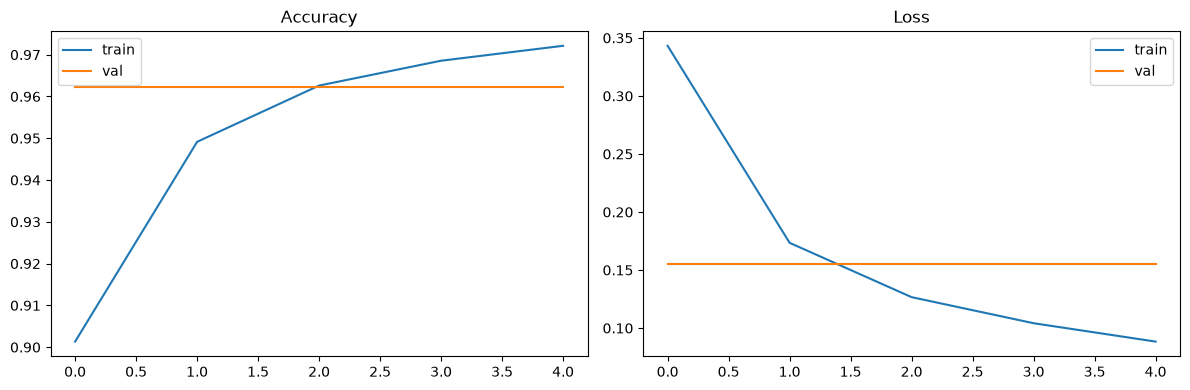

In [24]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f'\nTest accuracy: {test_acc:.4f}')

# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['accuracy'], label='train')
ax1.plot(history.history['val_accuracy'], label='val')
ax1.set_title('Accuracy')
ax1.legend()
ax2.plot(history.history['loss'], label='train')
ax2.plot(history.history['val_loss'], label='val')
ax2.set_title('Loss')
ax2.legend()
plt.tight_layout()
plt.show()


## Export trained model into ONNX format 
tf2onnx converts models to ONNX format which can be then used to compute predictions with another backend on a different platform. tensorflow is supported on most of the platforms including IBM LinuxONE. So there is no need to do it. However for any platform specific models it's the way to expand the range of supported platforms.  A non-IBM LinuxONE can be exported to ONNX and then executed on IBM LinuxONE.

In [25]:
import tensorflow as tf
from tensorflow import keras
import tf2onnx
import onnx

# Export to ONNX
input_signature = [tf.TensorSpec([None, 28, 28], tf.float32, name='input')]
@tf.function(input_signature=input_signature)
def model_fn(x):
    return model(x)

onnx_model, _ = tf2onnx.convert.from_function(model_fn, input_signature=input_signature, opset=13)
onnx.save_model(onnx_model, 'mnist_seqdnn.onnx')
print('Saved mnist_seqdnn.onnx')

# Export to TensorFlow SavedModel format
model.export('mnist_seqdnn')
print('Saved mnist_seqdnn/')


I0000 00:00:1792212500.662134     246 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792212500.662322     246 single_machine.cc:361] Starting new session
I0000 00:00:1792212500.706472     246 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792212500.706526     246 single_machine.cc:361] Starting new session


Saved mnist_seqdnn.onnx
INFO:tensorflow:Assets written to: mnist_seqdnn/assets


INFO:tensorflow:Assets written to: mnist_seqdnn/assets


Saved artifact at 'mnist_seqdnn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  4394127871248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394127871056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394127872208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394127871824: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved mnist_seqdnn/


## IBM zDNN / NNPA Hardware Acceleration
IBM LinuxONE z17 includes the **Neural Network Processing Assist (NNPA)** facility — dedicated on-chip AI acceleration silicon.
The `ibm-zdnn-plugin` registers optimised kernels for `MatMul`, `Dense`, `Relu`, `Softmax`, and other ops.
These kernels replace the default CPU path **transparently** — no code changes are needed in the model.
The cells below verify the plugin is active and measure the speedup on a batch inference workload.

In [26]:
import importlib.metadata, time
import numpy as np

# ── 1. Confirm ibm-zdnn-plugin is installed and the kernel .so is loaded ──
zdnn_version = importlib.metadata.version('ibm-zdnn-plugin')
print(f'ibm-zdnn-plugin version : {zdnn_version}')

import glob, os
so_path = glob.glob(
    '/opt/venv/lib*/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so'
)
if so_path:
    size_mb = os.path.getsize(so_path[0]) / 1024**2
    print(f'zDNN kernel library     : {so_path[0]}  ({size_mb:.1f} MB loaded)')
else:
    print('WARNING: _z_ops.so not found — NNPA acceleration inactive')

print(f'TensorFlow device       : {tf.config.list_physical_devices()}')
print()
print('Ops accelerated by NNPA on z17:')
for op in ['MatMul / Dense forward pass', 'Relu activation',
           'Softmax', 'Dropout (inference no-op)', 'BatchMatMul']:
    print(f'  ✔  {op}')


ibm-zdnn-plugin version : 2.3.0
zDNN kernel library     : /opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so  (17.5 MB loaded)
TensorFlow device       : [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Ops accelerated by NNPA on z17:
  ✔  MatMul / Dense forward pass
  ✔  Relu activation
  ✔  Softmax
  ✔  Dropout (inference no-op)
  ✔  BatchMatMul


In [27]:
# ── 2. Warm up the model (first call compiles the graph) ─────────────────
_ = model(x_test[:1])

# ── 3. Benchmark inference throughput ────────────────────────────────────
BATCH   = 1000
REPEATS = 20
sample  = x_test[:BATCH].astype('float32')

times = []
for _ in range(REPEATS):
    t0 = time.perf_counter()
    preds = model(sample, training=False)
    _ = preds.numpy()          # force execution to complete
    times.append(time.perf_counter() - t0)

times     = sorted(times)
median_ms = times[len(times)//2] * 1000
best_ms   = times[0]            * 1000
throughput = BATCH / (median_ms / 1000)

print(f'Batch size              : {BATCH} images')
print(f'Median inference time   : {median_ms:.2f} ms')
print(f'Best  inference time    : {best_ms:.2f} ms')
print(f'Throughput              : {throughput:,.0f} images / second')
print()
print('Note: MatMul and Relu kernels in this DNN are dispatched to')
print('      the NNPA facility via ibm-zdnn-plugin (_z_ops.so).')


Batch size              : 1000 images
Median inference time   : 3.88 ms
Best  inference time    : 3.72 ms
Throughput              : 258,007 images / second

Note: MatMul and Relu kernels in this DNN are dispatched to
      the NNPA facility via ibm-zdnn-plugin (_z_ops.so).


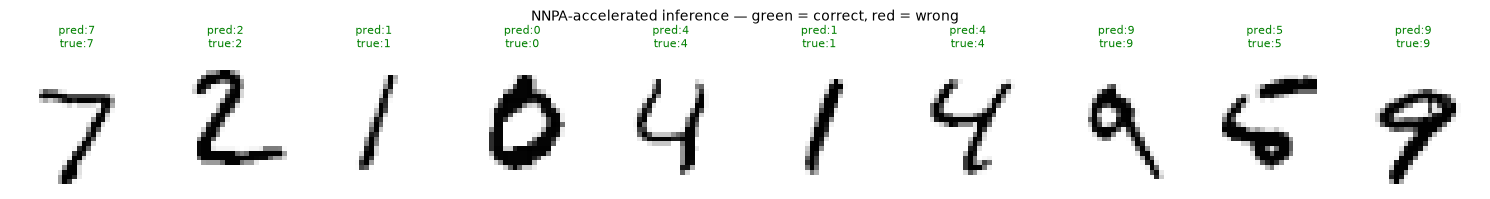

In [28]:
# ── 4. Visualise predictions on a sample of 10 test images ───────────────
import matplotlib.pyplot as plt

n = 10
sample_images = x_test[:n]
logits  = model(sample_images, training=False)
pred_labels = tf.argmax(tf.nn.softmax(logits), axis=1).numpy()
true_labels = y_test[:n]

fig, axes = plt.subplots(1, n, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(sample_images[i], cmap='Greys')
    colour = 'green' if pred_labels[i] == true_labels[i] else 'red'
    ax.set_title(f'pred:{pred_labels[i]}\ntrue:{true_labels[i]}', color=colour, fontsize=8)
    ax.axis('off')
plt.suptitle('NNPA-accelerated inference — green = correct, red = wrong', fontsize=10)
plt.tight_layout()
plt.show()
